In [9]:
%load_ext autoreload
%autoreload 2

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from wiki_forecast.evaluation import summarize
from wiki_forecast.features import FEATURES, build_dataset, to_log_wide
from wiki_forecast.global_model import global_backtest

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [10]:
df = pd.read_parquet("../data/raw/pageviews.parquet")
log_wide = to_log_wide(df)

HORIZONS = range(1, 29)
RESULTS_DIR = Path("../data/results")

classical = pd.read_parquet(RESULTS_DIR / "classical_oktoberfest.parquet")
cutoffs = pd.DatetimeIndex(sorted(classical["cutoff"].unique()))
print(f"{len(cutoffs)} cutoffs from {cutoffs[0].date()} to {cutoffs[-1].date()}")

55 cutoffs from 2022-08-10 to 2026-09-30


In [11]:
global_train = build_dataset(
    log_wide, pd.date_range("2018-01-01", log_wide.index[-1], freq="14D"), HORIZONS
)

okt_wide = log_wide[["Oktoberfest"]]
single_train = build_dataset(
    okt_wide, pd.date_range("2018-01-01", log_wide.index[-1], freq="D"), HORIZONS
)

print(f"global: {len(global_train):,} rows | single: {len(single_train):,} rows")

global: 3,449,712 rows | single: 90,468 rows


In [12]:
def cached(path: Path, compute):
    """Load results if saved, otherwise compute and save them."""
    if path.exists():
        print(f"loaded {path.name}")
        return pd.read_parquet(path)
    result = compute()
    result.to_parquet(path, index=False)
    return result


global_results = cached(
    RESULTS_DIR / "lgbm_global.parquet",
    lambda: global_backtest(log_wide, global_train, cutoffs, HORIZONS, "lgbm_global"),
)
single_results = cached(
    RESULTS_DIR / "lgbm_single_oktoberfest.parquet",
    lambda: global_backtest(okt_wide, single_train, cutoffs, HORIZONS, "lgbm_single"),
)

loaded lgbm_global.parquet
loaded lgbm_single_oktoberfest.parquet


In [13]:
variants = {
    "lgbm_global_corr": [*FEATURES, "season_corr"],
    "lgbm_global_id": [*FEATURES, "article"],
    "lgbm_global_corr_id": [*FEATURES, "season_corr", "article"],
}

variant_results = {
    name: cached(
        RESULTS_DIR / f"{name}.parquet",
        lambda feats=feats, name=name: global_backtest(
            log_wide, global_train, cutoffs, HORIZONS, name, features=feats
        ),
    )
    for name, feats in variants.items()
}

lgbm_global_corr: trained on 1,730,216 rows up to 2022-08-10 in 25s
lgbm_global_corr: trained on 1,913,260 rows up to 2023-01-25 in 25s
lgbm_global_corr: trained on 2,097,674 rows up to 2023-07-12 in 29s
lgbm_global_corr: trained on 2,282,882 rows up to 2023-12-27 in 29s
lgbm_global_corr: trained on 2,468,690 rows up to 2024-06-12 in 31s
lgbm_global_corr: trained on 2,654,498 rows up to 2024-11-27 in 33s
lgbm_global_corr: trained on 2,840,306 rows up to 2025-05-14 in 35s
lgbm_global_corr: trained on 3,026,114 rows up to 2025-10-29 in 38s
lgbm_global_corr: trained on 3,211,922 rows up to 2026-04-15 in 41s
lgbm_global_corr: trained on 3,397,730 rows up to 2026-09-30 in 43s
lgbm_global_id: trained on 1,730,216 rows up to 2022-08-10 in 26s
lgbm_global_id: trained on 1,913,260 rows up to 2023-01-25 in 28s
lgbm_global_id: trained on 2,097,674 rows up to 2023-07-12 in 31s
lgbm_global_id: trained on 2,282,882 rows up to 2023-12-27 in 33s
lgbm_global_id: trained on 2,468,690 rows up to 2024-06-

In [14]:
okt = pd.concat(
    [
        classical,
        single_results.drop(columns="article"),
        *[
            r[r["article"] == "Oktoberfest"].drop(columns="article")
            for r in [global_results, *variant_results.values()]
        ],
    ],
    ignore_index=True,
)
okt["year"] = okt["date"].dt.year
festival = okt[okt["date"].dt.month.isin([9, 10])]

display(summarize(okt))
display(summarize(festival))
okt.groupby("year").apply(summarize, include_groups=False)

,MAE,MASE
model,,
prophet_events,251.374954,0.548454
lgbm_single,292.260929,0.642221
prophet,336.981980,0.737504
mstl,398.356955,0.872801
snaive_364,410.302597,0.900873
lgbm_global_corr,412.973915,0.904759
lgbm_global_corr_id,418.860301,0.918596
lgbm_global_id,449.026881,0.985026
mstl_no_log,581.102725,1.265338


,MAE,MASE
model,,
prophet_events,732.601333,1.610310
lgbm_single,1065.391508,2.360117
prophet,1158.547964,2.551596
snaive_364,1252.052980,2.770621
mstl,1403.919737,3.101599
lgbm_global_corr,1636.143415,3.600268
lgbm_global_corr_id,1701.892372,3.746744
lgbm_global_id,1851.679305,4.077077
mstl_no_log,1886.309179,4.144932


MAE      MASE
year model                               
2022 prophet_events  591.563507  1.301296
     prophet         757.622775  1.671224
     mstl            760.685119  1.681187
     snaive_364      847.349650  1.861063
     mstl_no_log     966.409555  2.104940
...                         ...       ...
2026 mstl_no_log     398.570395  0.883804
     theta           535.367656  1.191163
     ets             538.803875  1.198587
     arima           671.074509  1.488760
     snaive_364      702.056478  1.558314

[65 rows x 2 columns]

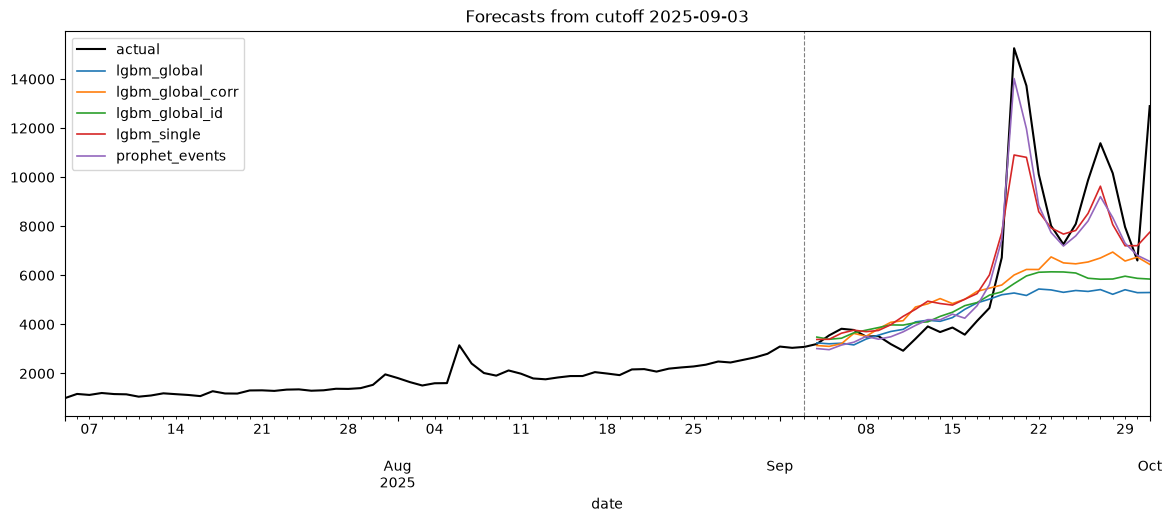

In [15]:
SHOW = ["prophet_events", "lgbm_single", "lgbm_global", "lgbm_global_corr", "lgbm_global_id"]
s = np.expm1(log_wide["Oktoberfest"])

c = min(okt["cutoff"].unique(), key=lambda x: abs(x - pd.Timestamp("2025-09-10")))
fold = okt[(okt["cutoff"] == c) & okt["model"].isin(SHOW)]

fig, ax = plt.subplots(figsize=(14, 5))
s[c - pd.Timedelta(days=60) : fold["date"].max()].plot(ax=ax, color="black", lw=1.5, label="actual")
for name, g in fold.groupby("model"):
    ax.plot(g["date"], g["pred"], lw=1.2, label=name)
ax.axvline(c, color="gray", ls="--", lw=0.8)
ax.set_title(f"Forecasts from cutoff {c.date()}")
ax.legend()
plt.show()

In [16]:
raw = np.expm1(log_wide)
same_day_last_year = raw.shift(364).unstack()  # indexed by (article, date)
idx = pd.MultiIndex.from_arrays([global_results["article"], global_results["date"]])
baseline = global_results.assign(
    model="snaive_364", pred=same_day_last_year.reindex(idx).to_numpy()
)

# Compare only on rows where the baseline exists (articles need 1 year of history).
has_baseline = baseline["pred"].notna().to_numpy()
both = pd.concat([global_results[has_baseline], baseline[has_baseline]], ignore_index=True)

per_article_vs_snaive = (
    both.assign(abs_err=(both["actual"] - both["pred"]).abs())
    .groupby(["article", "model"])["abs_err"].mean()
    .unstack()
)
ratio = per_article_vs_snaive["lgbm_global"] / per_article_vs_snaive["snaive_364"]
print(f"Global better on {(ratio < 1).mean():.0%} of articles")
print(f"Median ratio:    {ratio.median():.2f}")
print(f"Geometric mean:  {np.exp(np.log(ratio).mean()):.2f}")

display(ratio.sort_values().head(10))   # where global helps most
display(ratio.sort_values().tail(10))   # where it's worst

Global better on 99% of articles
Median ratio:    0.50
Geometric mean:  0.48


article
Deaths_in_2024                    0.096569
Israel–Hamas_war                  0.097579
List_of_American_films_of_2025    0.119757
Ukraine                           0.128081
Deaths_in_2023                    0.129412
2023                              0.149326
Johnny_Depp                       0.150472
2023_in_film                      0.153960
Pathaan_(film)                    0.154560
List_of_Hindi_films_of_2025       0.154901
dtype: float64

article
List_of_states_and_territories_of_the_United_States    0.835243
Mariah_Carey                                           0.840347
Macaulay_Culkin                                        0.861539
George_Washington                                      0.887816
List_of_Super_Bowl_champions                           1.414221
Martin_Luther_King_Jr.                                 1.420747
Oktoberfest                                            1.440366
National_Football_League                               1.472802
List_of_UFC_events                                     1.494098
Windows_10_version_history                             2.393104
dtype: float64

In [17]:
all_global = pd.concat([global_results, *variant_results.values()], ignore_index=True)
per_article = (
    all_global.assign(abs_err=(all_global["actual"] - all_global["pred"]).abs())
    .groupby(["article", "model"])["abs_err"].mean()
    .unstack()
)

ratio_vs_base = per_article.drop(columns="lgbm_global").div(per_article["lgbm_global"], axis=0)
display(pd.DataFrame({
    "geo_mean_ratio": np.exp(np.log(ratio_vs_base).mean()),
    "share_improved": (ratio_vs_base < 1).mean(),
}))

seasonal = [
    "Oktoberfest", "List_of_Super_Bowl_champions", "Martin_Luther_King_Jr.",
    "National_Football_League", "Mariah_Carey", "Macaulay_Culkin",
    "George_Washington", "List_of_UFC_events",
]
per_article.loc[seasonal].round(0)

,geo_mean_ratio,share_improved
model,,
lgbm_global_corr,0.997132,0.582278
lgbm_global_corr_id,0.978916,0.661844
lgbm_global_id,0.978372,0.660036


model,lgbm_global,lgbm_global_corr,lgbm_global_corr_id,lgbm_global_id
article,,,,
Oktoberfest,591.0,413.0,419.0,449.0
List_of_Super_Bowl_champions,9083.0,8930.0,9013.0,8917.0
Martin_Luther_King_Jr.,3909.0,3770.0,3380.0,3359.0
National_Football_League,2073.0,1921.0,2063.0,2063.0
Mariah_Carey,3630.0,3360.0,3094.0,3095.0
Macaulay_Culkin,7184.0,6523.0,5731.0,5703.0
George_Washington,2013.0,1973.0,1833.0,1817.0
List_of_UFC_events,3199.0,3162.0,2419.0,2426.0
